In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython import display
from tqdm import tqdm
import numpy as np
from scipy.stats import yulesimon, linregress

In [2]:
DATA = Path('../data/external')
CACHE = DATA / 'cache'
cleaned_papers = pd.read_parquet(DATA / 'papers_cleaned.gencat.parquet')
cleaned_papers = cleaned_papers.drop_duplicates(subset="doi").reset_index(drop=True)


In [3]:
cleaned_papers

,date,doi,ruct,orcidResearchers,orcidUncheckedAuthors,orcidDirectors
0,1949-01-01T00:00:00.000,10.1210/jcem-9-9-883,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
1,1952-01-01T00:00:00.000,10.1002/cber.19520850704,Universitat Rovira i Virgili,[0000-0001-6112-5913],None,None
2,1952-01-01T00:00:00.000,10.1111/j.1365-2133.1952.tb15900.x,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
3,1953-01-01T00:00:00.000,10.1038/jid.1953.55,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
4,1954-01-01T00:00:00.000,10.1016/s0022-5347(17)67795-4,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
...,...,...,...,...,...,...
358034,2021-12-31T00:00:00.000,10.48489/quadrante.23878,Universitat de Barcelona,"[0000-0001-7228-6210, 0000-0001-9756-116X]",None,None
358035,2022-01-01T00:00:00.000,10.1002/uog.24977,Institut de Recerca Sant Joan de Déu,[0000-0002-0069-7640],None,None
358036,2022-01-01T00:00:00.000,10.21203/rs.3.rs-957988/v1,Universitat de Vic - Universitat Central de Ca...,"[0000-0002-6743-2161, 0000-0003-3419-7174, 000...",None,None
358037,2022-01-01T00:00:00.000,10.1344/anpsic2022.52/2.3,Universitat de Barcelona,[0000-0003-1280-4578],None,None


In [4]:
cleaned_papers['date'] = pd.to_datetime(cleaned_papers['date'])
print(min(cleaned_papers['date'].dt.year))
print(max(cleaned_papers['date'].dt.year))

1949
2026


In [5]:
#year_df = cleaned_papers[cleaned_papers['date'].dt.year == 2021]
exploded_papers = cleaned_papers.explode('orcidResearchers')
grouped = exploded_papers['orcidResearchers'].value_counts() 
grouped

orcidResearchers
0000-0002-7215-0150    1472
0000-0002-8873-0491    1195
0000-0002-9511-5999    1116
0000-0001-6571-4096    1084
0000-0002-0394-5646     965
                       ... 
0000-0003-2849-1801       1
0000-0002-4178-8266       1
0000-0002-3517-6116       1
0000-0001-7169-8002       1
0000-0002-6947-0460       1
Name: count, Length: 29458, dtype: int64

In [6]:
vc = grouped.value_counts().sort_index()            # counts per value, ascending x

dif = pd.DataFrame({
    "value": vc.index,
    "count": vc.values,
})
dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
# optional: "fraction >= x" instead of "> x"
dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

In [7]:
dif

,value,count,cdf,surv,surv_ge
0,1,4082,0.138570,0.861430,1.000000
1,2,2686,0.229751,0.770249,0.861430
2,3,1987,0.297203,0.702797,0.770249
3,4,1560,0.350160,0.649840,0.702797
4,5,1386,0.397210,0.602790,0.649840
...,...,...,...,...,...
409,965,1,0.999864,0.000136,0.000170
410,1084,1,0.999898,0.000102,0.000136
411,1116,1,0.999932,0.000068,0.000102
412,1195,1,0.999966,0.000034,0.000068


In [8]:
def f(data, rho):
    N = len(data)
    double_sum = 0
    for k in data:
        for j in range(1, k+1):
            double_sum = double_sum + 1 / (rho + j)
    return N / double_sum 

In [9]:
rho_0 = 0 # initial guess
epsilon = 0.00000001 # tolerance

converged = False
while not converged:
    rho_1 = f(grouped.values, rho_0)
    converged = abs(rho_1 - rho_0) < epsilon
    rho_0 = rho_1
    print(rho_1)
mle_rho = rho_1
vc = grouped.value_counts().sort_index()
est_probs = yulesimon.pmf(vc.index, 0.8) # Probabilities

0.3484566629878861
0.4042548213817874
0.4123921703605101
0.413563929308483
0.41373235522894586
0.41375655810450296
0.4137600359382406
0.4137605356836566
0.41376060749368304
0.4137606178119118
0.4137606192952064


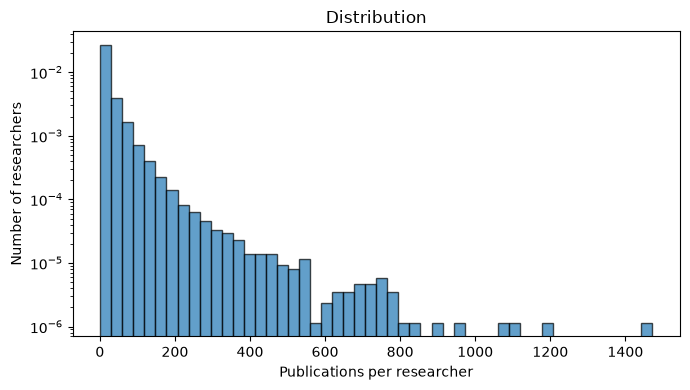

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))

vc = grouped.value_counts().sort_index()

ax.hist(grouped,bins=50, edgecolor='black', density = True, alpha=0.7)
#ax.plot(vc.index,est_probs)
ax.set_title('Distribution')
ax.set_yscale('log')
#ax.set_xscale('log')
ax.set_xlabel('Publications per researcher')
ax.set_ylabel('Number of researchers')
#ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

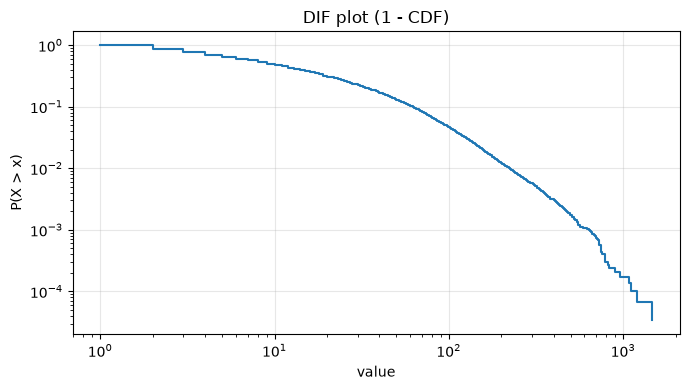

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(dif["value"], dif["surv_ge"], where="post")
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.set_xscale("log")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

In [12]:
papers_y = []
researchers_y = []
for year_paper in range(min(cleaned_papers['date'].dt.year),max(cleaned_papers['date'].dt.year)+1):
    year_df = cleaned_papers[cleaned_papers['date'].dt.year == year_paper]
    exploded_papers = year_df.explode('orcidResearchers')
    grouped = exploded_papers['orcidResearchers'].value_counts() 
    vc = grouped.value_counts().sort_index()            # counts per value, ascending x
    
    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })
    dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
    # optional: "fraction >= x" instead of "> x"
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()
    papers_y.append(dif["value"])
    researchers_y.append(dif["surv_ge"])
print(len(papers_y))
print(len(researchers_y))

78
78


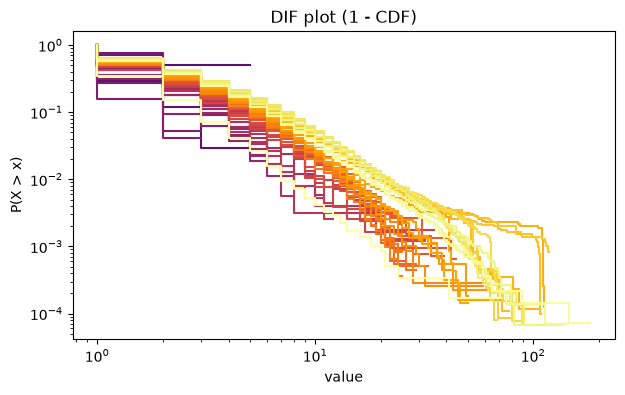

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()

In [14]:
papers_y = []
researchers_y = []
areas = []
mean_res = []
mean_pap = []

for year_paper in range(
    cleaned_papers['date'].dt.year.min(),
    cleaned_papers['date'].dt.year.max() + 1
):
    year_df = cleaned_papers[
        cleaned_papers['date'].dt.year == year_paper
    ]

    exploded_papers = year_df.explode('orcidResearchers')
    grouped = exploded_papers['orcidResearchers'].value_counts()
    vc = grouped.value_counts().sort_index()

    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })

    dif["cdf"] = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"] = 1 - dif["cdf"]
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

    x = dif["value"].to_numpy(dtype=float)
    y = dif["surv_ge"].to_numpy(dtype=float)

    # Area under the curve
    area = np.trapezoid(x, y)

    # Normalize so area = 1
    if area < 0:
        x_norm = x / (-area)
    else:
        x_norm = x
    
    papers_y.append(x_norm)
    researchers_y.append(y)
    areas.append(area)

print(len(papers_y))
print(len(researchers_y))
#print("Original areas:", areas)

78
78


In [15]:
#researchers_y

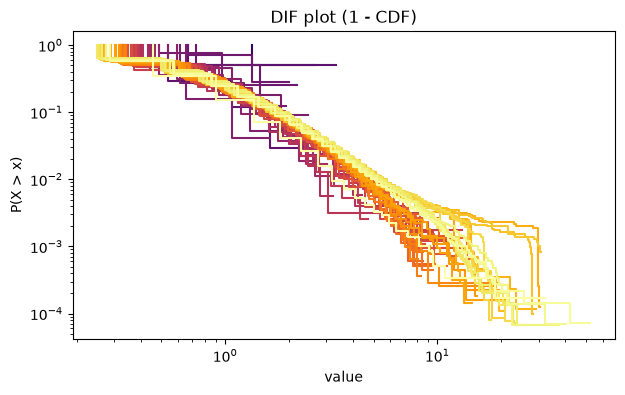

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()